# Banking Risk Analysis – Exploratory Data Analysis
Load the `customer` table from SQL Server, check data quality, and explore the clients' profiles, loans and deposits.

## 1. Connect to SQL Server and load the data

In [1]:
import pandas as pd                           # library to work with tables
import matplotlib.pyplot as plt               # charts
import seaborn as sns                         # statistical charts
from sqlalchemy import create_engine          # creates the database connection
from urllib.parse import quote_plus           # encodes special characters in the password
from getpass import getpass                   # asks for the password without saving it

# Connection details
username = "sa"                               # SQL Server user
password = quote_plus(getpass("SQL Server password: "))   # typed at runtime, never stored
host = "127.0.0.1"                            # Docker SQL Server on this Mac
port = "1433"                                 # default SQL Server port
database = "banking_project"                  # database created in banking_project.sql

# Create the connection engine
engine = create_engine(f"mssql+pymssql://{username}:{password}@{host}:{port}/{database}")

# Read the customer table into a DataFrame
df = pd.read_sql("SELECT * FROM customer;", engine)
df.head()                                     # show the first 5 rows

,Client_ID,Name,Age,Location_ID,Joined_Bank,Banking_Contact,Nationality,Occupation,Fee_Structure,Loyalty_Classification,...,Bank_Deposits,Checking_Accounts,Saving_Accounts,Foreign_Currency_Account,Business_Lending,Properties_Owned,Risk_Weighting,BRId,GenderId,IAId
0,IND81288,Raymond Mills,24,34324,2019-05-06,Anthony Torres,American,Safety Technician IV,High,Jade,...,1485828.64,603617.88,607332.46,12249.96,1134475.30,1,2,1,1,1
1,IND65833,Julia Spencer,23,42205,2001-12-10,Jonathan Hawkins,African,Software Consultant,High,Jade,...,641482.79,229521.37,344635.16,61162.31,2000526.10,1,3,2,1,2
2,IND47499,Stephen Murray,27,7314,2010-01-25,Anthony Berry,European,Help Desk Operator,High,Gold,...,1033401.59,652674.69,203054.35,79071.78,548137.58,1,3,3,2,3
3,IND72498,Virginia Garza,40,34594,2019-03-28,Steve Diaz,American,Geologist II,Mid,Silver,...,1048157.49,1048157.49,234685.02,57513.65,1148402.29,0,4,4,1,4
4,IND60181,Melissa Sanders,46,41269,2012-07-20,Shawn Long,American,Assistant Professor,Mid,Platinum,...,487782.53,446644.25,128351.45,30012.14,1674412.12,0,3,1,2,5


## 2. Explore the dataset structure

In [2]:
print("Shape:", df.shape)    # (rows, columns) -> (3000, 25)
df.info()                    # data types and non-null counts

Shape: (3000, 25)
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Client_ID                 3000 non-null   str    
 1   Name                      3000 non-null   str    
 2   Age                       3000 non-null   int64  
 3   Location_ID               3000 non-null   int64  
 4   Joined_Bank               3000 non-null   object 
 5   Banking_Contact           3000 non-null   str    
 6   Nationality               3000 non-null   str    
 7   Occupation                3000 non-null   str    
 8   Fee_Structure             3000 non-null   str    
 9   Loyalty_Classification    3000 non-null   str    
 10  Estimated_Income          3000 non-null   float64
 11  Superannuation_Savings    3000 non-null   float64
 12  Amount_of_Credit_Cards    3000 non-null   int64  
 13  Credit_Card_Balance       3000 non-null   float64
 14  B

## 3. Check missing values

In [3]:
df.isnull().sum()    # count missing values in each column -> 0 everywhere

Client_ID                   0
Name                        0
Age                         0
Location_ID                 0
Joined_Bank                 0
Banking_Contact             0
Nationality                 0
Occupation                  0
Fee_Structure               0
Loyalty_Classification      0
Estimated_Income            0
Superannuation_Savings      0
Amount_of_Credit_Cards      0
Credit_Card_Balance         0
Bank_Loans                  0
Bank_Deposits               0
Checking_Accounts           0
Saving_Accounts             0
Foreign_Currency_Account    0
Business_Lending            0
Properties_Owned            0
Risk_Weighting              0
BRId                        0
GenderId                    0
IAId                        0
dtype: int64

## 4. Fix data types

In [4]:
# Amounts: make sure DECIMAL columns from SQL Server are numeric (float)
money_cols = ['Estimated_Income', 'Superannuation_Savings', 'Credit_Card_Balance',
              'Bank_Loans', 'Bank_Deposits', 'Checking_Accounts', 'Saving_Accounts',
              'Foreign_Currency_Account', 'Business_Lending']
df[money_cols] = df[money_cols].astype(float)

# Date: text -> real date (SQL Server already returns it as YYYY-MM-DD)
df['Joined_Bank'] = pd.to_datetime(df['Joined_Bank'])

df.dtypes    # check: float64 and datetime64

Client_ID                             str
Name                                  str
Age                                 int64
Location_ID                         int64
Joined_Bank                 datetime64[s]
Banking_Contact                       str
Nationality                           str
Occupation                            str
Fee_Structure                         str
Loyalty_Classification                str
Estimated_Income                  float64
Superannuation_Savings            float64
Amount_of_Credit_Cards              int64
Credit_Card_Balance               float64
Bank_Loans                        float64
Bank_Deposits                     float64
Checking_Accounts                 float64
Saving_Accounts                   float64
Foreign_Currency_Account          float64
Business_Lending                  float64
Properties_Owned                    int64
Risk_Weighting                      int64
BRId                                int64
GenderId                          

## 5. Summary statistics

In [5]:
df.describe()    # mean, std, min, quartiles, max of numeric columns

,Age,Location_ID,Joined_Bank,Estimated_Income,Superannuation_Savings,Amount_of_Credit_Cards,Credit_Card_Balance,Bank_Loans,Bank_Deposits,Checking_Accounts,Saving_Accounts,Foreign_Currency_Account,Business_Lending,Properties_Owned,Risk_Weighting,BRId,GenderId,IAId
count,3000.000000,3000.000000,3000,3000.000000,3000.000000,3000.000000,3000.000000,3.000000e+03,3.000000e+03,3.000000e+03,3.000000e+03,3000.000000,3.000000e+03,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,51.039667,21563.323000,2010-08-15 00:03:21,171305.034263,25531.599673,1.463667,3176.206943,5.913862e+05,6.715602e+05,3.210929e+05,2.329084e+05,29883.529993,8.667598e+05,1.518667,2.249333,2.559333,1.504000,10.425333
min,17.000000,12.000000,1995-01-03 00:00:00,15919.480000,1482.030000,1.000000,1.170000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,45.000000,0.000000e+00,0.000000,1.000000,1.000000,1.000000,1.000000
25%,34.000000,10803.500000,2004-04-01 18:00:00,82906.595000,12513.775000,1.000000,1236.630000,2.396281e+05,2.044004e+05,1.199475e+05,7.479440e+04,11916.542500,3.748251e+05,1.000000,1.000000,2.000000,1.000000,5.000000
50%,51.000000,21129.500000,2011-02-18 00:00:00,142313.480000,22357.355000,1.000000,2560.805000,4.797934e+05,4.633165e+05,2.428157e+05,1.640866e+05,24341.190000,7.113147e+05,2.000000,2.000000,3.000000,2.000000,10.000000
75%,69.000000,32054.500000,2017-12-24 06:00:00,242290.305000,35464.740000,2.000000,4522.632500,8.258130e+05,9.427546e+05,4.348749e+05,3.155750e+05,41966.392500,1.185110e+06,2.000000,3.000000,3.000000,2.000000,15.000000
max,85.000000,43369.000000,2021-12-31 00:00:00,522330.260000,75963.900000,3.000000,13991.990000,2.667557e+06,3.890598e+06,1.969923e+06,1.724118e+06,124704.870000,3.825962e+06,3.000000,5.000000,4.000000,2.000000,22.000000
std,19.854760,12462.273017,NaN,111935.808209,16259.950770,0.676387,2497.094709,4.575570e+05,6.457169e+05,2.820796e+05,2.300078e+05,23109.924010,6.412303e+05,1.102145,1.131191,1.007713,0.500067,5.988242


## 6. Create income bands (Low / Mid / High)

Income_Band
Mid     1517
Low     1027
High     456
Name: count, dtype: int64


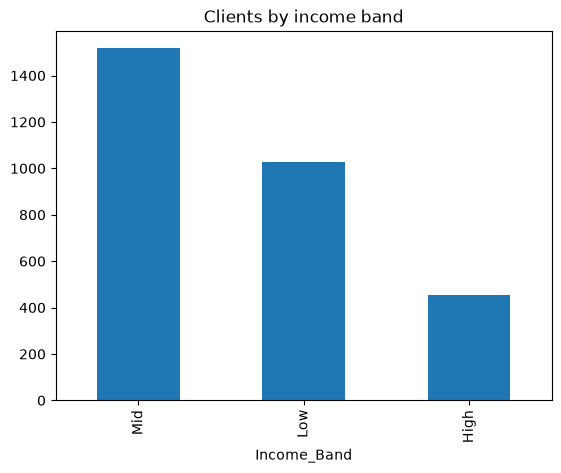

In [6]:
bins = [0, 100000, 300000, float('inf')]                  # band limits
labels = ['Low', 'Mid', 'High']                           # band names
df['Income_Band'] = pd.cut(df['Estimated_Income'], bins=bins, labels=labels, right=False)

print(df['Income_Band'].value_counts())                   # clients per band
df['Income_Band'].value_counts().plot(kind='bar', title='Clients by income band')
plt.show()

## 7. Univariate analysis – categorical columns

In [7]:
categorical_cols = ['BRId', 'GenderId', 'IAId', 'Amount_of_Credit_Cards', 'Nationality',
                    'Occupation', 'Fee_Structure', 'Loyalty_Classification',
                    'Properties_Owned', 'Risk_Weighting', 'Income_Band']

for col in categorical_cols:                              # count values in each column
    print(f"\nValue counts for '{col}':")
    print(df[col].value_counts())


Value counts for 'BRId':
BRId
3    1352
1     660
2     495
4     493
Name: count, dtype: int64

Value counts for 'GenderId':
GenderId
2    1512
1    1488
Name: count, dtype: int64

Value counts for 'IAId':
IAId
1     177
2     177
3     177
4     177
8     177
9     176
10    176
11    176
12    176
13    176
14    176
15    176
5      89
6      89
7      89
16     88
17     88
18     88
19     88
20     88
21     88
22     88
Name: count, dtype: int64

Value counts for 'Amount_of_Credit_Cards':
Amount_of_Credit_Cards
1    1922
2     765
3     313
Name: count, dtype: int64

Value counts for 'Nationality':
Nationality
European      1309
Asian          754
American       507
Australian     254
African        176
Name: count, dtype: int64

Value counts for 'Occupation':
Occupation
Associate Professor             28
Structural Analysis Engineer    28
Recruiter                       25
Account Coordinator             24
Human Resources Manager         24
                                ..

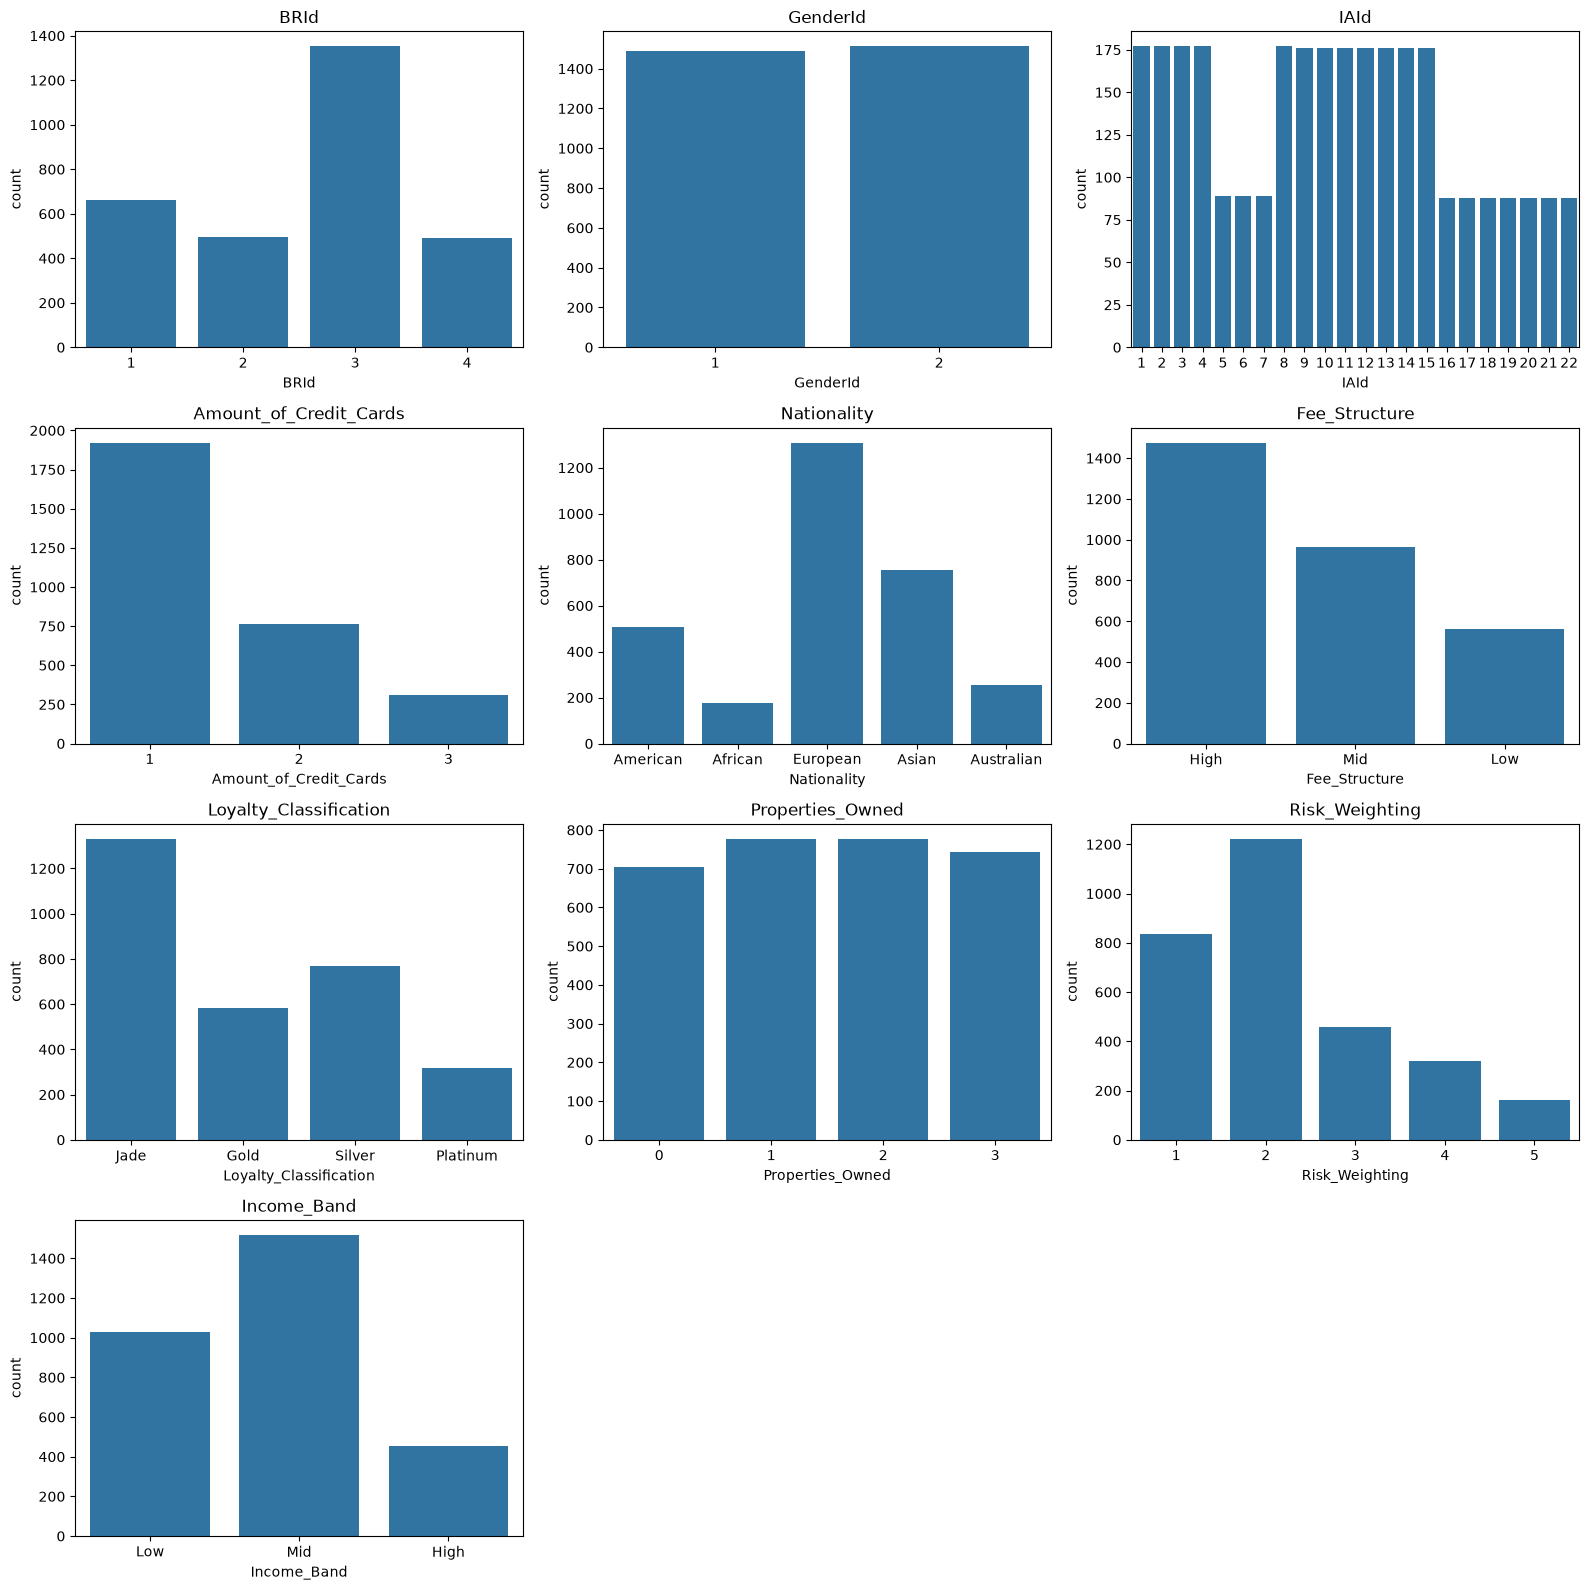

In [8]:
plot_cols = [c for c in categorical_cols if c != 'Occupation']   # Occupation has too many values

fig, axes = plt.subplots(4, 3, figsize=(16, 16))          # one chart per column
axes = axes.flatten()
for ax, col in zip(axes, plot_cols):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)
for ax in axes[len(plot_cols):]:                          # hide empty slots
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## 8. Bivariate analysis – categorical columns by nationality

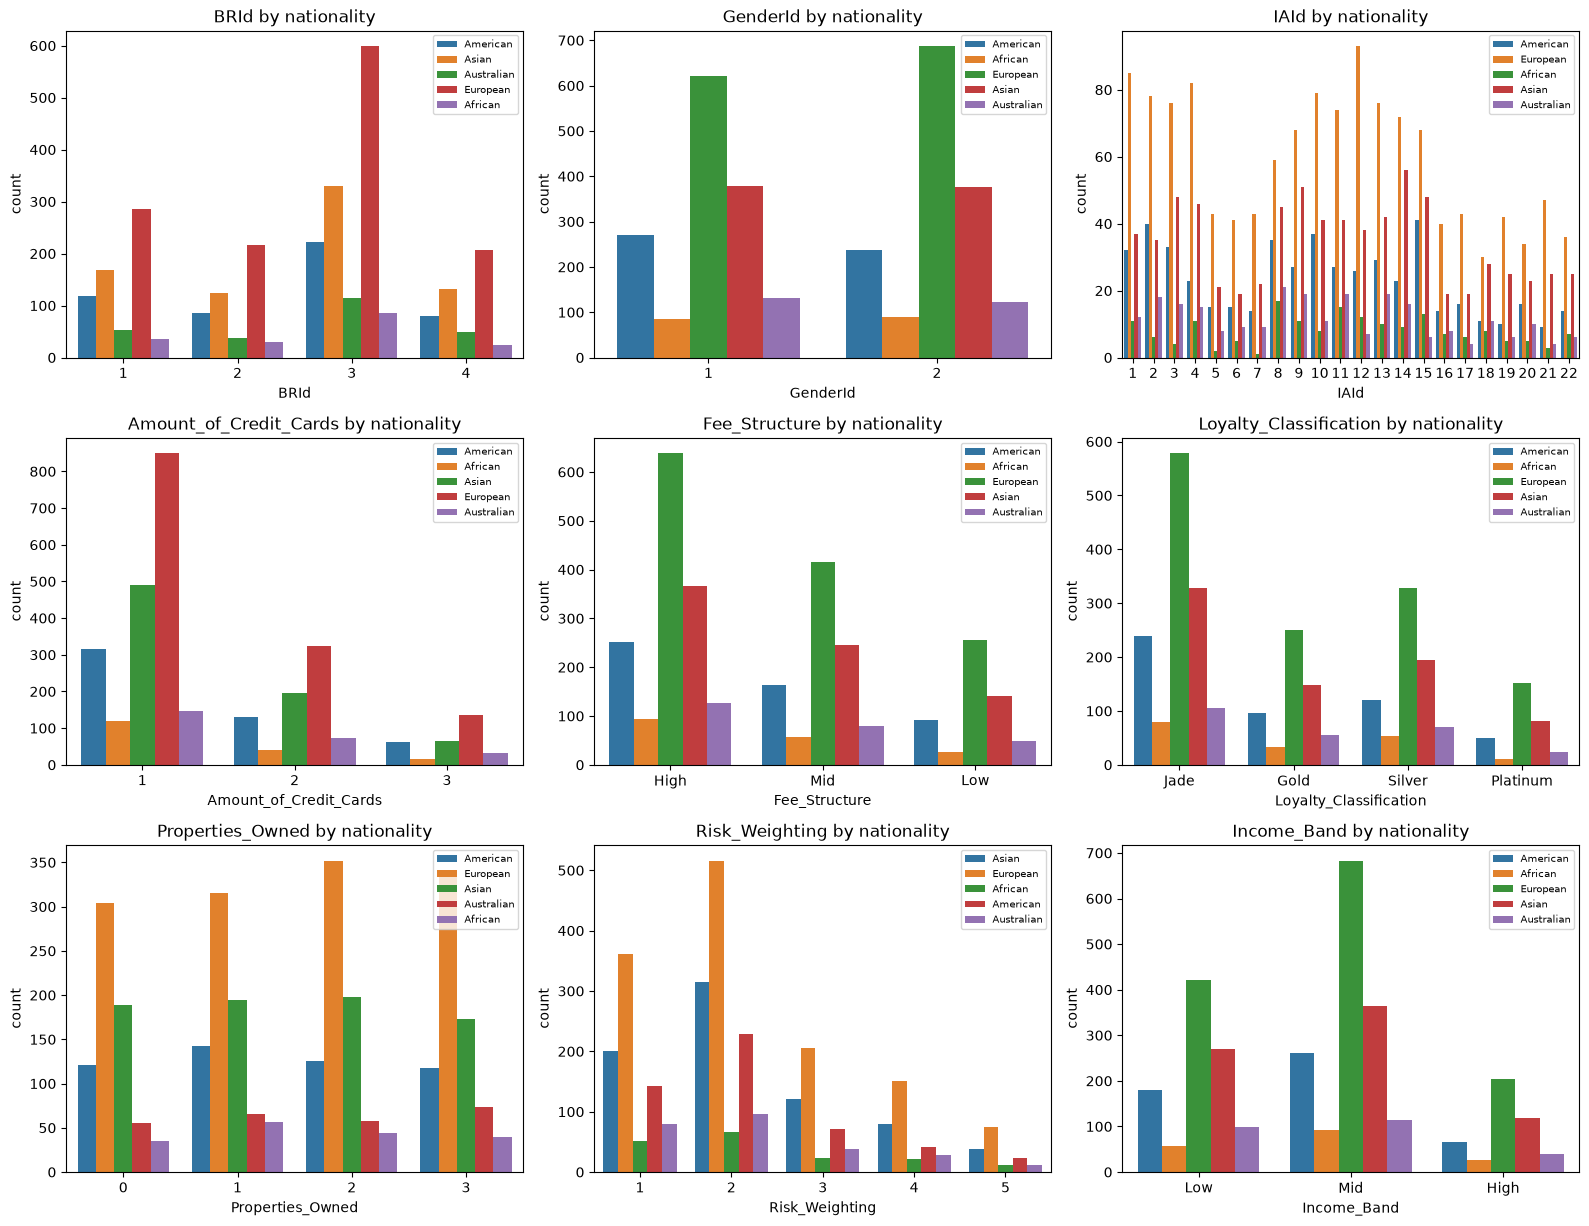

In [9]:
hue_cols = [c for c in plot_cols if c != 'Nationality']

fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.flatten()
for ax, col in zip(axes, hue_cols):
    sns.countplot(data=df, x=col, hue='Nationality', ax=ax)   # split each bar by nationality
    ax.set_title(f'{col} by nationality')
    ax.legend(fontsize=7)
for ax in axes[len(hue_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## 9. Univariate analysis – numerical columns

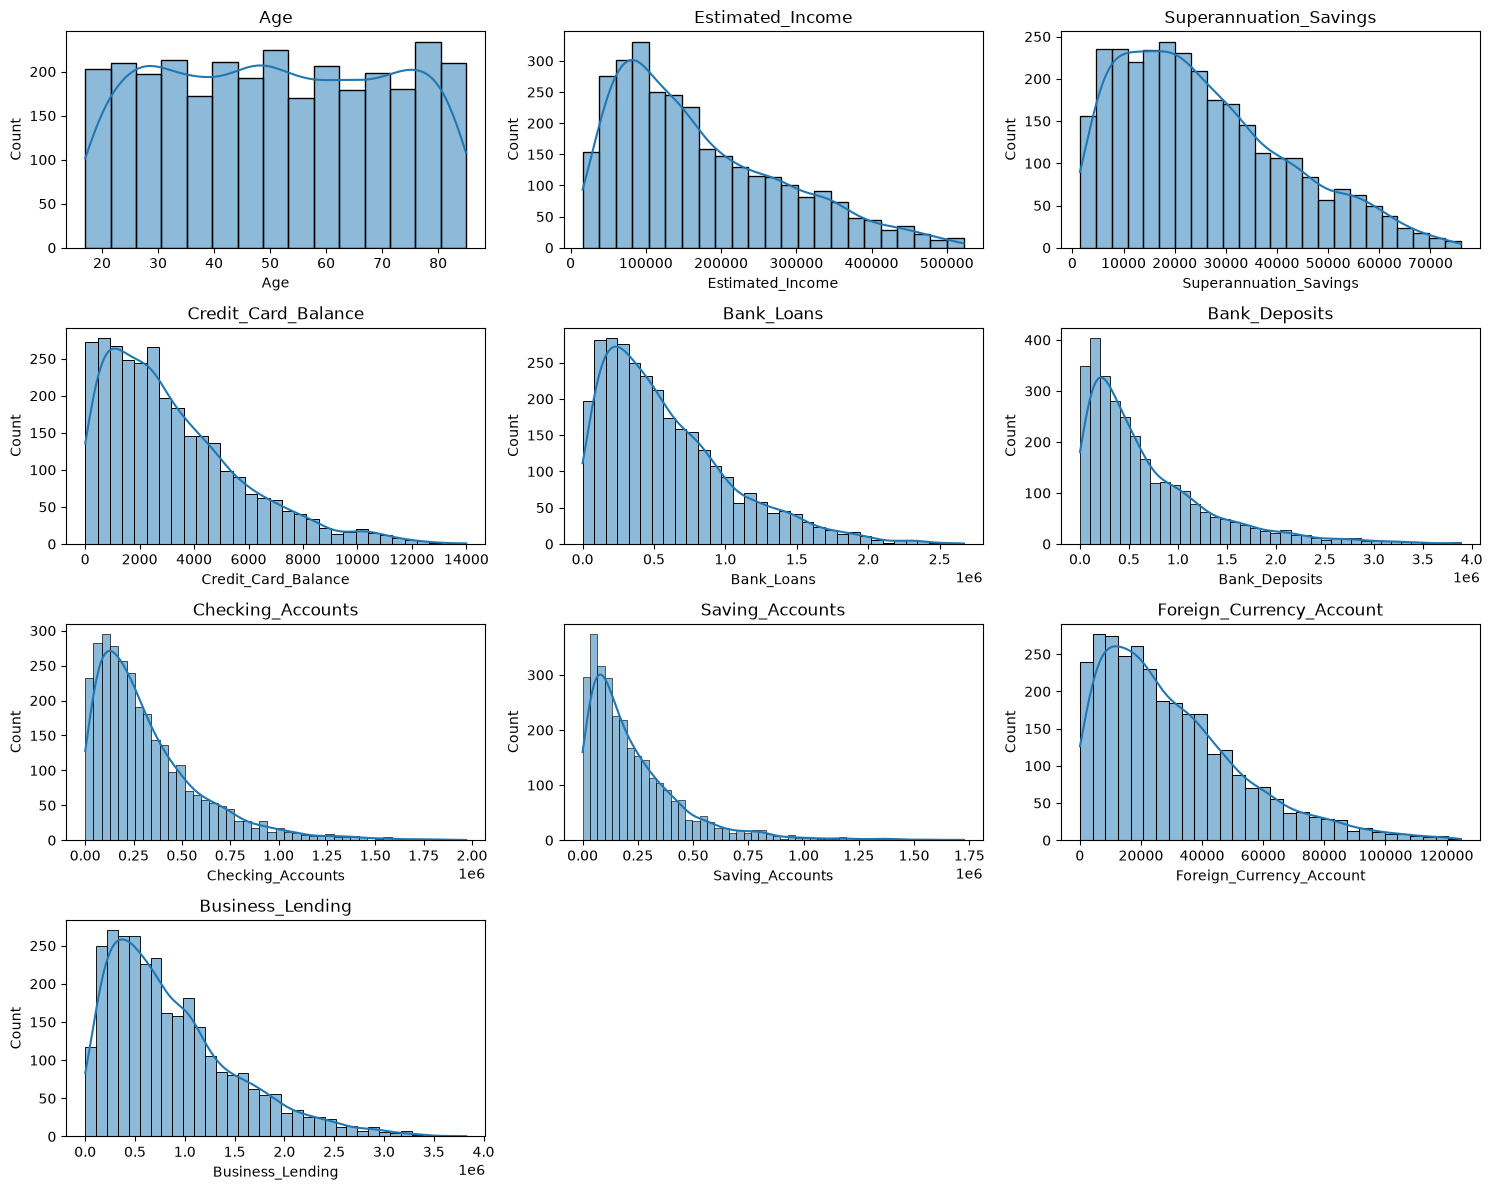

In [10]:
numerical_cols = ['Age', 'Estimated_Income', 'Superannuation_Savings', 'Credit_Card_Balance',
                  'Bank_Loans', 'Bank_Deposits', 'Checking_Accounts', 'Saving_Accounts',
                  'Foreign_Currency_Account', 'Business_Lending']

plt.figure(figsize=(15, 12))
for i, col in enumerate(numerical_cols):                  # histogram + density curve
    plt.subplot(4, 3, i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

## 10. Correlation matrix

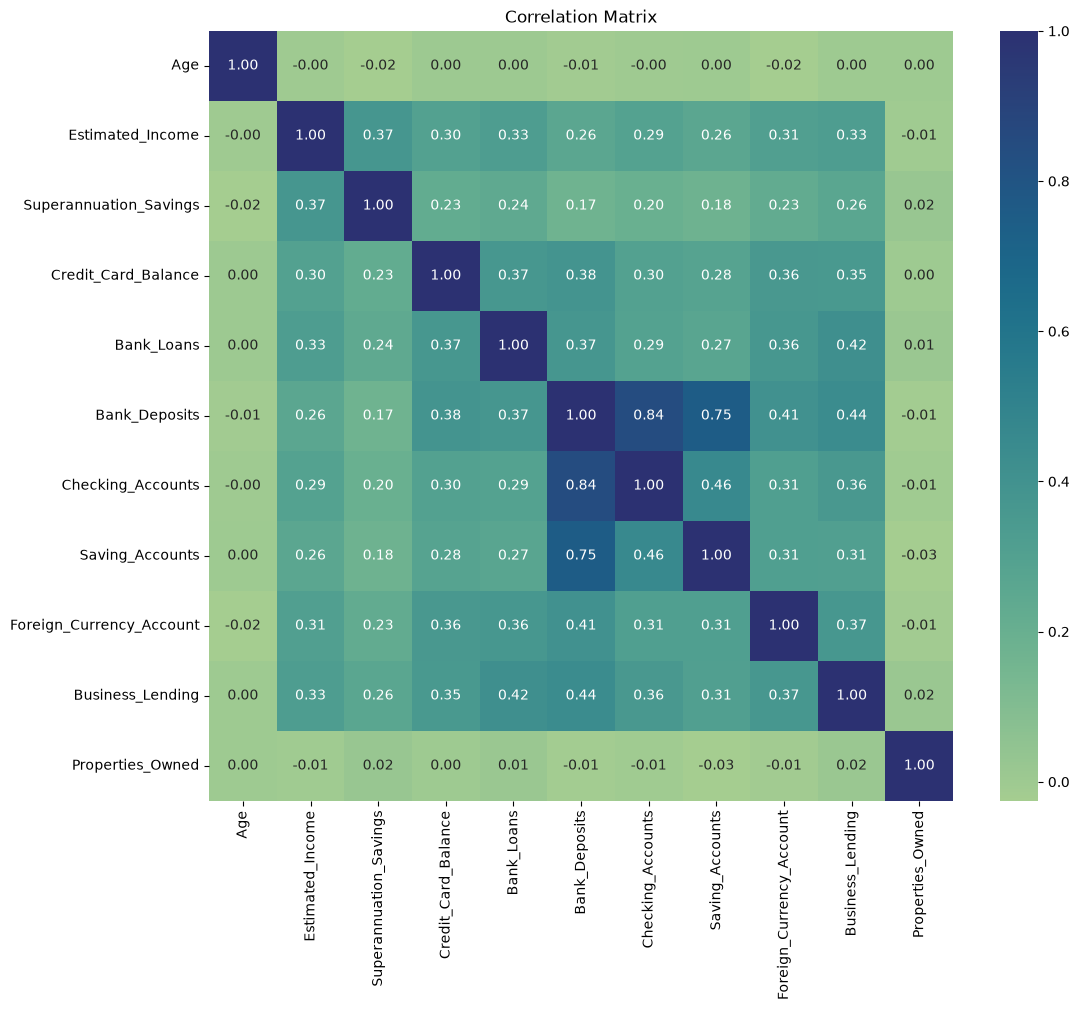

In [11]:
correlation_matrix = df[numerical_cols + ['Properties_Owned']].corr()   # -1 to 1

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='crest', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

## 11. Scatter plots with trend line

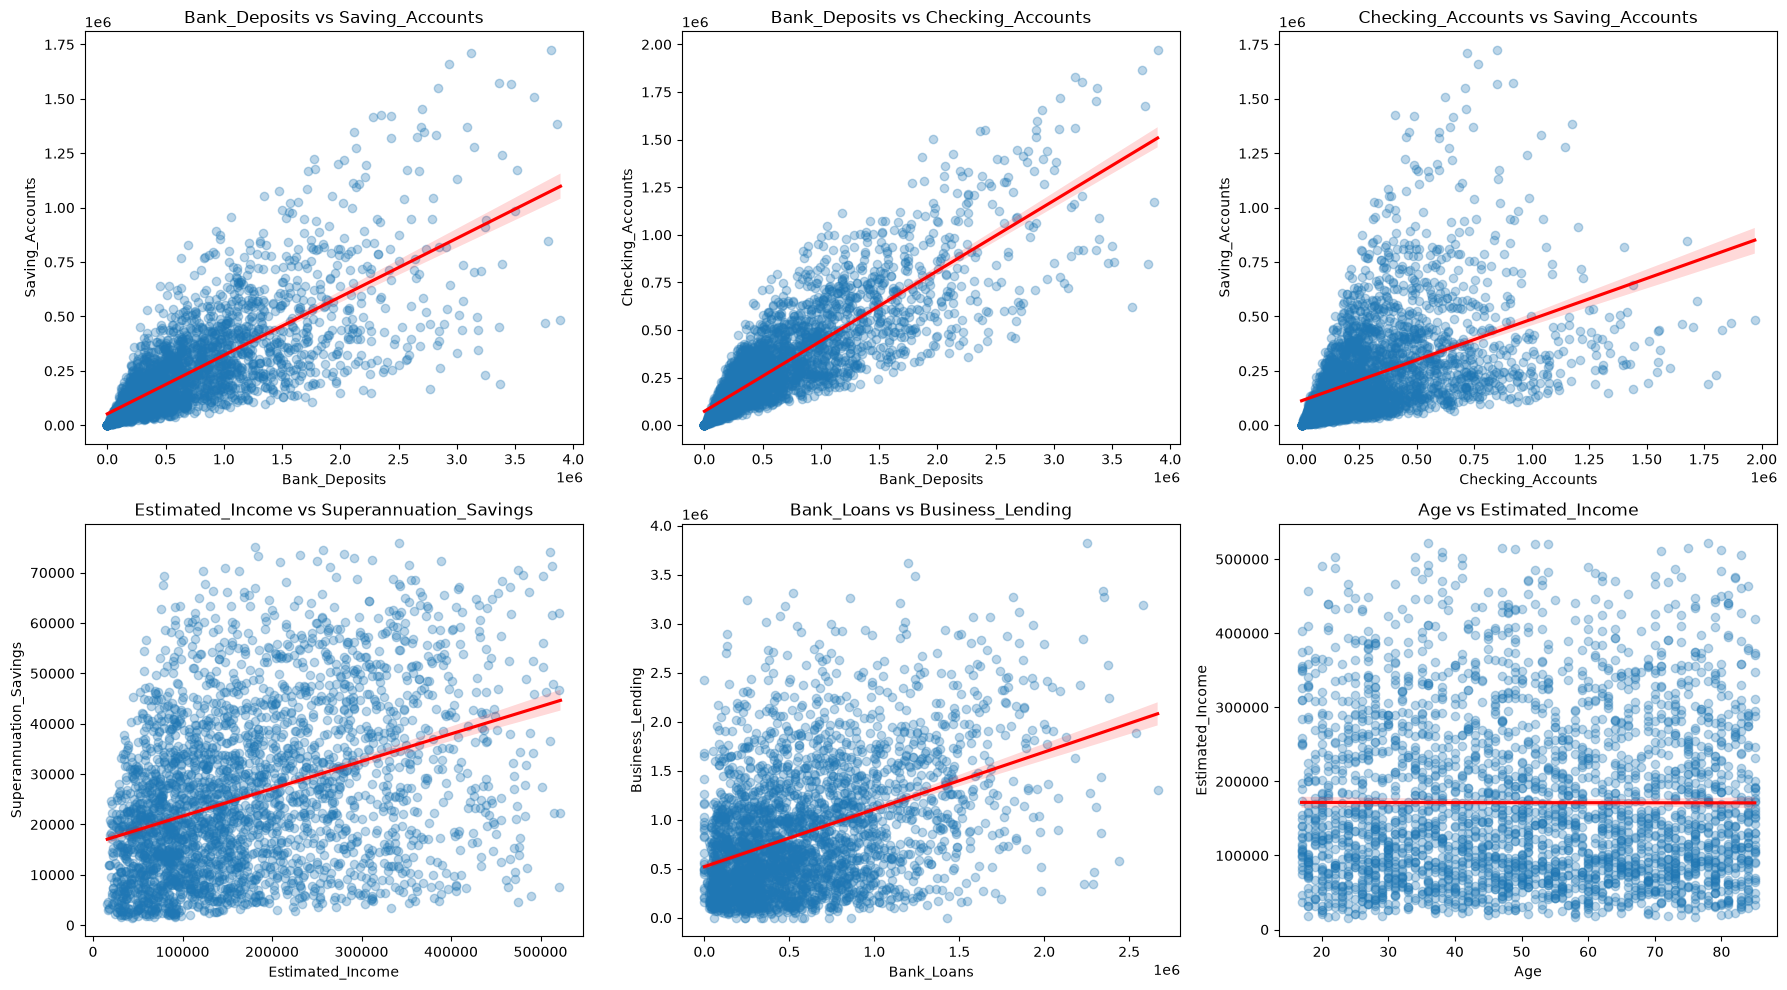

In [12]:
pairs = [('Bank_Deposits', 'Saving_Accounts'), ('Bank_Deposits', 'Checking_Accounts'),
         ('Checking_Accounts', 'Saving_Accounts'), ('Estimated_Income', 'Superannuation_Savings'),
         ('Bank_Loans', 'Business_Lending'), ('Age', 'Estimated_Income')]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for ax, (x, y) in zip(axes, pairs):
    sns.regplot(data=df, x=x, y=y, ax=ax, scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})
    ax.set_title(f'{x} vs {y}')
plt.tight_layout()
plt.show()

## 12. Insights

- **Deposits and accounts**: very strong correlation between Bank_Deposits and Checking_Accounts (0.84) and Saving_Accounts (0.75). Clients who deposit a lot also keep high balances on their checking and savings accounts.
- **Income**: moderate correlation (≈0.3) between income and every balance or loan. Higher earners hold and borrow more, but income alone does not decide it.
- **Loans**: Bank_Loans and Business_Lending are linked (0.42). Big borrowers use several lending products, so credit risk is concentrated on a smaller group of clients.
- **Age**: no correlation with any amount (≈0). Age does not explain wealth or debt in this dataset.
- **Distributions**: all amounts are right-skewed (many small values, a few very large ones), especially Saving_Accounts.
- **Client base**: 51% Mid income, 34% Low, 15% High; 64% hold a single credit card; 44% are European; the Private Bank relationship (BRId 3) is the largest segment.